# Summary

The important points to know from this week are:

- The assumptions under pinning discrete time Geometric Brownian motion, the difference equation used to simulate the log of the stock price and the importance of the terms appearing in it.
- Simulating discrete time Geometric Brownian motion in Python and using fan diagrams to visualise how the distribution of the stock price changes with time.
- The \(von Neumann Morgernstern utility theorem and how we can use utility functions to capture risk and preference over outcomes.
- Showing the optimal consumption and investment proportions for the infinite horizon Merton problem are independent of time, wealth and the stock price.



In [1]:
import numpy as np
import matplotlib .pyplot as plt
import math

rng = np.random.default_rng(2026)


## Geometric Brownian Motion (GBM)

**Definition**

Geometric Brownian Motion (GBM) is a stochastic model used to describe the evolution of stock prices over time. It assumes that log returns are independent and normally distributed.

**Financial Applications**

- **Option Pricing:** Modelling stock prices in the Black–Scholes framework to value European options.
- **Risk Management:** Simulating future stock prices to estimate potential losses and Value at Risk (VaR).
- **Investment Optimisation:** Comparing consumption and investment strategies, such as in the Merton problem.

**Core Equation**

Let $Z_t = \log S_t$. The discrete-time GBM model is:

$$
Z_{t+\Delta t}
=
Z_t+
\left(\mu-\frac{1}{2}\sigma^2\right)\Delta t
+\sigma\sqrt{\Delta t}\epsilon_t
$$

where:

- $\mu$: stock-price drift
- $\sigma$: volatility
- $\Delta t$: time-step size
- $\epsilon_t \sim N(0,1)$: independent standard normal shocks

The stock price is recovered using:

$$
S_t=e^{Z_t}
$$

**Key Properties**

$$
E[S_t]=S_0e^{\mu t}
$$

The mean and variance of log returns increase linearly with time, while their standard deviation increases with the square root of time.

> **Notes：** GBM models log-price changes rather than stock-price changes directly. The term $-\frac{1}{2}\sigma^2$ adjusts the log-price drift so that the expected stock price grows at rate $\mu$. GBM predicts a distribution of possible future prices, not an exact future price.


In [2]:
def simulate_gbm(S0, mu, sigma, T, n_steps):
    dt = T / n_steps
    Z = np.zeros(n_steps+1)
    Z[0] = np.log(S0)
    epsilon = rng.standard_normal(n_steps)

    for i in range(n_steps):
        Z[i+1] = Z[i] + (mu - 0.5* sigma**2) *dt + sigma * np.sqrt(dt) * epsilon[i]
    
    return np.exp(Z)

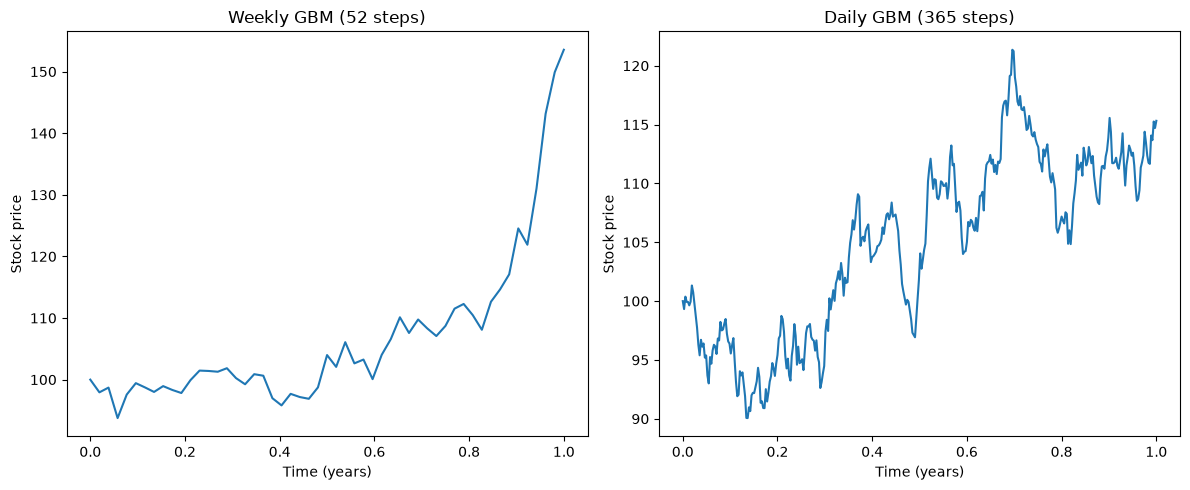

In [3]:
S0, mu, sigma, T = 100, 0.08, 0.2, 1

n_steps = 52
S_week = simulate_gbm(S0, mu, sigma, T, n_steps)
times_week = np.linspace(0, T, n_steps + 1)

n_steps = 365
S_day = simulate_gbm(S0, mu, sigma, T, n_steps)
times_day = np.linspace(0, T, n_steps + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(times_week, S_week)
axes[1].plot(times_day, S_day)

for ax in axes:
    ax.set(xlabel="Time (years)", ylabel="Stock price")

axes[0].set_title("Weekly GBM (52 steps)")
axes[1].set_title("Daily GBM (365 steps)")

fig.tight_layout()


### Simulating Multiple GBM Paths

We extend the previous function by introducing `n_paths`, allowing us to simulate multiple possible stock-price paths.

**Why simulate multiple paths?**

A single simulated path represents only one possible future outcome. By generating many independent scenarios, we can estimate the distribution of future stock prices.

This allows us to:

- Estimate expected stock prices and percentiles.
- Assess potential losses and market risk.
- Evaluate investment strategies using Monte Carlo simulation.

**Array Structure**

`S.shape = (n_paths, n_steps + 1)`

- Rows represent different scenarios.
- Columns represent different time points.

> **Notes：** Each path represents one possible market scenario. More paths generally improve the precision of Monte Carlo estimates, while more time steps provide a finer time grid.


In [4]:
def simulate_gbm_paths(S0, mu, sigma, T, n_steps, n_paths):
    dt = T / n_steps
    times = np.linspace(0, T, n_steps+1)
    Z = np.zeros((n_paths, n_steps+1))
    Z[:, 0] = np.log(S0)
    epsilon = rng.standard_normal((n_paths, n_steps))

    for i in range(n_steps):
        Z[:, i+1] = Z[:, i] + (mu - 0.5* sigma**2) *dt + sigma * np.sqrt(dt) * epsilon[:, i]
    
    return np.exp(Z),times

S, times = simulate_gbm_paths(S0,mu,sigma,T,365,2000)   # times = n + 1

print(S.shape)

(2000, 366)



### Visualising Simulated Stock Prices

**Percentiles and Fan Diagram**

We use `np.percentile(S, [5, 50, 95], axis=0)` to calculate the stock-price percentiles at each time point across all simulated scenarios.

- **5th percentile:** Lower bound of the central 90% range.
- **50th percentile:** Median stock price.
- **95th percentile:** Upper bound of the central 90% range.

`fill_between(x, y1, y2)` fills the area between two curves. Here, it visualises the range between the 5th and 95th percentiles.

**Interpretation**

- **Left plot — Simulated Paths:** Shows 100 possible stock-price trajectories under the same GBM parameters.
- **Right plot — Fan Diagram:** Shows the median and the central 90% of simulated stock prices at each time point.

**Financial Application**

The fan diagram helps investors understand the uncertainty of future stock prices and assess potential downside risk.

> **Notes：** `axis=0` calculates percentiles across scenarios for each time point. The shaded band contains approximately 90% of simulated prices at each individual time, not necessarily 90% of complete paths.


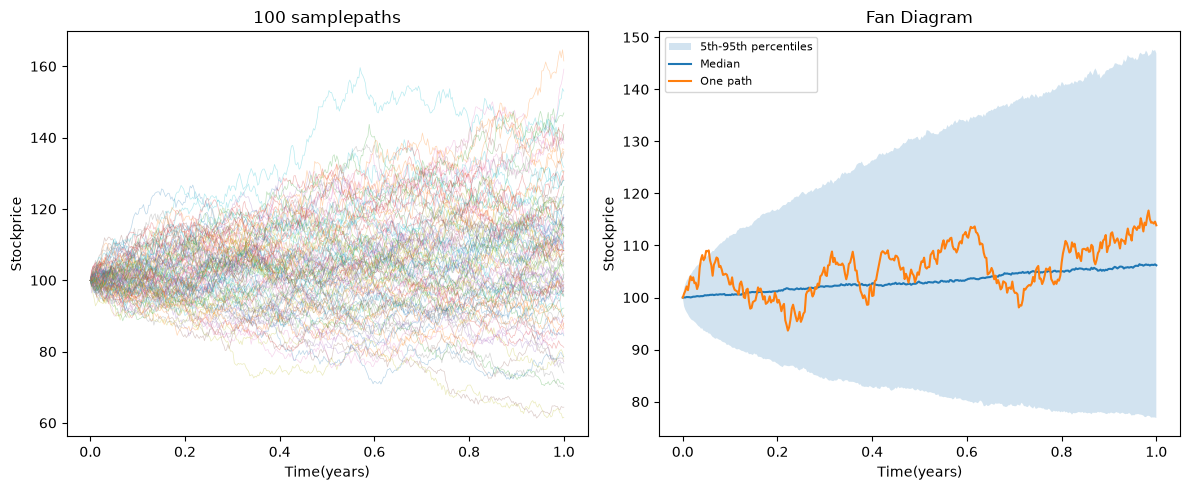

In [5]:
lower,median,upper=np.percentile(S,[5,50,95],axis=0) 
fig,axes= plt.subplots(1,2,figsize=(12,5)) 

axes[0].plot(times,S[:100].T,linewidth=0.5,alpha=0.3)   # Matplotlib plots each column of a 2D array as a separate line.
axes[0].set_title("100 samplepaths") 

axes[1].fill_between(times,lower,upper,alpha=0.2, label="5th-95th percentiles") 
axes[1].plot(times,median,label="Median") 
axes[1].plot(times,S[0],label="One path") 
axes[1].legend(fontsize=8) 
axes[1].set_title("Fan Diagram") 

for ax in axes: 
    ax.set(xlabel="Time(years)",ylabel="Stockprice") 

fig.tight_layout()


# Utility Functions

### Why Do We Need Utility Functions?

The Markowitz model compares portfolios using expected return and variance. However, mean and variance alone do not fully describe a general return distribution or an investor's preferences.

**Utility functions allow us to compare uncertain investment outcomes based on individual risk preferences.**

### Expected Utility and Preferences

According to the von Neumann–Morgenstern framework, preferences satisfying certain rationality axioms can be represented by maximising expected utility.

Let $W$ and $V$ represent uncertain future wealth under two investment strategies.

$$
W \prec V
\iff
E[u(W)] < E[u(V)]
$$

This means that the investor prefers strategy $V$ over strategy $W$.

A positive affine transformation does not change preferences:

$$
v(x)=Au(x)+B,\qquad A>0
$$

**Utility functions are typically increasing and concave:**

- **Increasing:** More wealth is preferred, so $u'(x)>0$.
- **Concave:** The investor is risk-averse, so $u''(x)<0$ for a strictly concave, twice-differentiable utility function.

By Jensen's inequality:

$$
E[u(W)]\le u(E[W])
$$

This means that a risk-averse investor prefers receiving the expected wealth with certainty to facing a risky outcome with the same expected wealth, or is indifferent.

> **Notes：** Utility 的绝对数值不重要，重要的是不同投资策略的 expected utility 排序。Concavity 表示 diminishing marginal utility，因此相同 expected wealth 下，投资者通常更偏好确定收益。

### Two Main Utility Functions

**1. Exponential Utility — CARA**

Constant Absolute Risk Aversion:

$$
u(x)=-e^{-\lambda x},\qquad \lambda>0
$$

The absolute risk-aversion coefficient is:

$$
A(x)=-\frac{u''(x)}{u'(x)}=\lambda
$$

- Larger $\lambda$ means greater risk aversion.
- Absolute risk aversion is independent of wealth.
- Adding the same fixed amount of cash to two investment outcomes does not change their preference ranking.

**2. Power / Logarithmic Utility — CRRA**

Constant Relative Risk Aversion:

A commonly used normalised form is:

$$
u(x)=
\begin{cases}
\frac{x^{1-\eta}-1}{1-\eta}, & \eta\ne1\\
\log x, & \eta=1
\end{cases}
$$

where $x>0$ and $\eta>0$.

The relative risk-aversion coefficient is:

$$
R(x)=-\frac{xu''(x)}{u'(x)}=\eta
$$

- Larger $\eta$ means greater risk aversion.
- Relative risk aversion is independent of wealth.
- Multiplying two investment outcomes by the same positive factor does not change their preference ranking.

> **Notes：** CARA 保持 absolute risk aversion 不变；CRRA 保持 relative risk aversion 不变。后面的 Merton Problem 使用 CRRA power utility，因为它具有 wealth scaling symmetry。

### Preferences over Time

Utility functions can also be used to evaluate consumption at different dates.

$$
U(\gamma)
=
E\left[
\sum_{t\in\mathcal{T}}
e^{-bt}u(\gamma_t)
\right]
$$

where:

- $\gamma_t$: consumption at time $t$
- $b>0$: utility discount rate
- $e^{-bt}$: discount factor applied to future utility

A larger $b$ assigns less weight to future consumption utility.

> **Notes：** 这为 Merton Problem 提供 objective function：投资者不仅关心财富增长，也关心不同时点的消费带来的 expected utility。


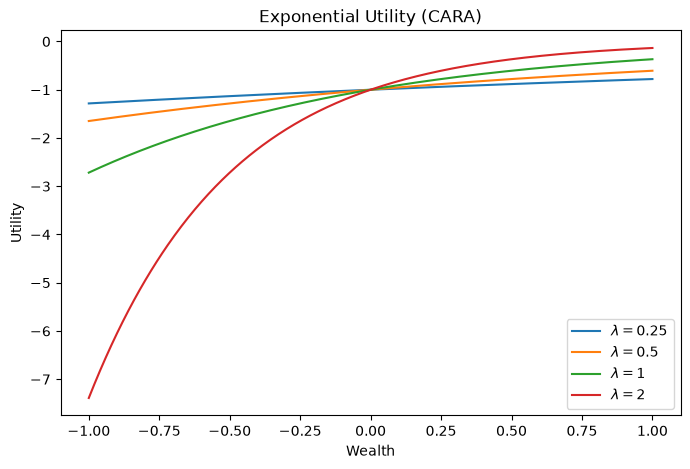

In [6]:
x = np.linspace(-1, 1, 500)

fig, ax = plt.subplots(figsize=(8, 5))

for lam in [0.25, 0.5, 1, 2]:
    u = -np.exp(-lam * x)
    ax.plot(x, u, label=rf"$\lambda={lam}$")

ax.set(
    xlabel="Wealth",
    ylabel="Utility",
    title="Exponential Utility (CARA)"
)
ax.legend()
plt.show()


##  The Merton Problem Continued

### 1. Consumption and Wealth Recursion

Under a constant-proportion strategy, wealth is divided into three parts at each date:

- **Consumption:** $p^\gamma W_t$
- **Stock investment:** $p^S W_t$
- **Bank investment:** $(1-p^\gamma-p^S)W_t$

The wealth recursion is:

$$
W_{t+\Delta t}
=
W_t\left[
p^S\frac{S_{t+\Delta t}}{S_t}
+
(1-p^\gamma-p^S)e^{r\Delta t}
\right]
$$

The investor consumes at each date and rebalances the remaining wealth using the same proportions.

> **Notes：** Consumption 已经从财富中扣除，因此不会参与下一期的财富增长。只有 Stock 和 Bank 两部分进入 Wealth Recursion。固定的是投资比例，而不是消费或投资的实际金额。

### 2/ Expected Utility by Monte Carlo Simulation

We estimate the expected discounted utility of a constant-proportion strategy by averaging across simulated consumption paths:

$$
\widehat U_M
=
\frac{1}{N}
\sum_{i=0}^{N-1}
\sum_{j=0}^{M-1}
e^{-bt_j}\gamma[i,j]^{1-\eta},
\qquad t_j=j\Delta t
$$

where:

- $N$: Number of simulated scenarios (`n_paths`).
- $M$: Number of time steps (`n_steps`).
- $\gamma[i,j]$: Consumption in scenario $i$ at time $t_j$.
- $b$: Utility discount rate.
- $\eta$: Relative risk-aversion coefficient.

**Implementation**

- `gamma[:, :-1]`: Exclude the final zero-consumption column.
- `sum(axis=1)`: Sum discounted utilities across dates within each scenario.
- `mean()`: Average total discounted utility across scenarios.

**Approximation Errors**

- **Sampling error:** Only finitely many simulated scenarios are used.
- **Truncation error:** Consumption utility from $T$ onwards is omitted.

> **Notes：** 先沿时间方向求和，再沿 scenarios 求平均。这里不乘 $\Delta t$，因为 $\gamma_t$ 表示每个日期实际消费的金额，而不是连续消费率。$T$ 只是 Infinite-Horizon Problem 的数值截断点，不是真正的最后消费日期。


In [7]:
def compute_consumption(W0, r, S, times, p_gamma, p_S):
    W = np.zeros(S.shape)               # S.shape: (2000, 366)
    W[:, 0] = W0
    consumption = np.zeros(S.shape)

    for i in range(len(times) - 1):     # times are discrete time points, and here we just need thire interval to calculate change
        consumption[:, i] = W[:, i] * p_gamma
        W[:, i+1] = W[:, i] * [p_S * (S[:, i+1]/ S[:, i]) + (1 - p_gamma - p_S) * np.exp(r* (times[i+1] - times[i]))]
    
    return consumption


In [8]:
def compute_expected_utility(W0, eta, r, S, times, p_gamma, p_S, b):

    gamma = compute_consumption(W0, r, S, times, p_gamma,p_S)

    discounted = np.exp(-b * times[ :-1]) * gamma[:, :-1]**(1 - eta)

    return discounted.sum(axis = 1).mean()


In [9]:
r,mu,sigma =0.02,0.08,0.7 
S0,W0,eta, b=100,1,0.5,0.10 
T,n_steps,n_paths=100,100,5000 

S,times=simulate_gbm_paths(S0,mu,sigma,T,n_steps,n_paths) 
U=compute_expected_utility(W0,eta,r,S,times,0.8,0.1,b) 

print(U)

1.5117952063505253



### 3. Plotting Feasible Proportions

Before numerical optimisation, we evaluate expected utility over a grid of feasible consumption and stock investment proportions.

**Feasible Region**

$$
p^\gamma\ge0,\qquad p^S\ge0,\qquad p^\gamma+p^S\le1
$$

These constraints form a triangular feasible region.

**Grid Construction**

For a grid of size $G$:

$$
p^\gamma=\frac{i}{G-1}
$$

$$
p^S=(1-p^\gamma)\frac{j}{G-1}
$$

where $i,j=0,\ldots,G-1$.

Each pair $(i,j)$ represents a candidate constant-proportion strategy.

**Expected Utility Surface**

For each feasible allocation, compute:

$$
\widehat U_M(p^\gamma,p^S)
$$

The three 2D arrays correspond to the coordinates of a 3D surface:

- X-axis: Consumption proportion.
- Y-axis: Stock investment proportion.
- Z-axis: Estimated expected utility.

**Common Random Numbers**

All strategies are evaluated using the same simulated stock-price paths to reduce Monte Carlo noise when comparing allocations.

> **Notes：** `p_gamma` 和 `p_S` 的二维矩阵是 Strategy Grid，不是 Time 或 Scenarios。每个 `(i,j)` 对应一组固定比例策略。左图展示 Feasible Region，右图展示不同策略的 Expected Utility。Grid Search 可以帮助定位大致最优区域，但不保证找到连续可行区域中的精确最优解。


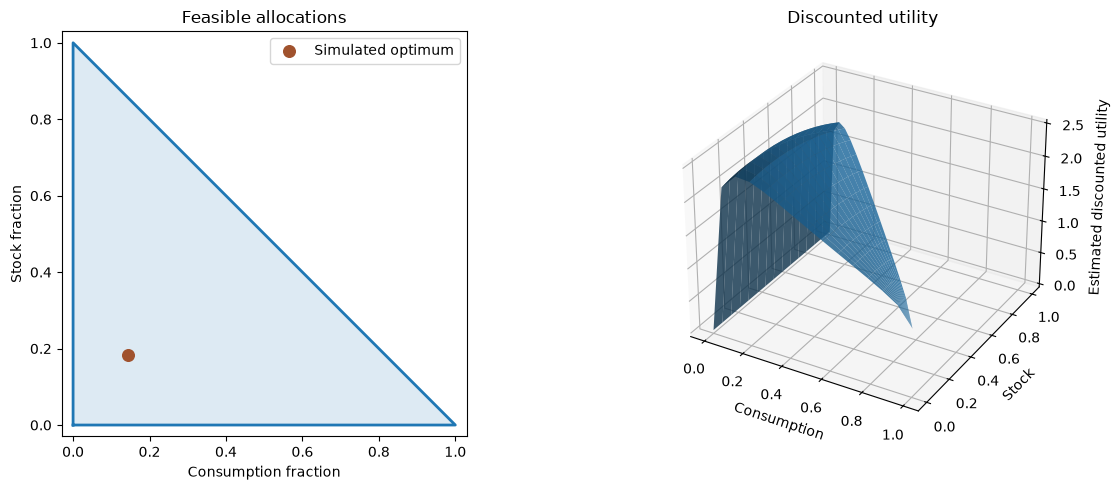

In [10]:
grid_size = 15
p_gamma = np.zeros((grid_size, grid_size))
p_S = np.zeros_like(p_gamma)
expected_utility = np.zeros_like(p_gamma)

for i in range(grid_size):
    for j in range(grid_size):
        p_gamma[i, j] = i / (grid_size - 1)
        p_S[i, j] = (1 - p_gamma[i, j]) * j / (grid_size - 1)
        expected_utility[i, j] = compute_expected_utility(
            W0, eta, r, S, times, p_gamma[i, j], p_S[i, j], b
        )

# Find the best allocation on the grid
best_idx = np.unravel_index(np.argmax(expected_utility), expected_utility.shape)
optimal_p_gamma = p_gamma[best_idx]
optimal_p_S = p_S[best_idx]

# Create two plots
fig = plt.figure(figsize=(13, 5))

# Left: Feasible allocations
ax1 = fig.add_subplot(1, 2, 1)

ax1.fill([0, 0, 1], [0, 1, 0], alpha=0.15)
ax1.plot([0, 0, 1, 0], [0, 1, 0, 0], linewidth=2)

ax1.scatter(optimal_p_gamma, optimal_p_S,
            color="sienna", s=70, label="Simulated optimum")

ax1.set_xlabel("Consumption fraction")
ax1.set_ylabel("Stock fraction")
ax1.set_title("Feasible allocations")
ax1.set_xlim(-0.03, 1.03)
ax1.set_ylim(-0.03, 1.03)
ax1.legend()
ax1.set_aspect("equal", adjustable="box")

# Right: Expected utility surface
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

ax2.plot_surface(p_gamma, p_S, expected_utility, alpha=0.8)

ax2.set_xlabel("Consumption")
ax2.set_ylabel("Stock")
ax2.set_zlabel("Estimated discounted utility")
ax2.set_title("Discounted utility")

plt.tight_layout()
plt.show()


### 4. Numerical Optimisation

We aim to maximise estimated expected utility:

$$
\max_{p^\gamma,p^S}\widehat U_M(p^\gamma,p^S)
$$

Since SciPy's `minimize()` searches for a minimum, we equivalently solve:

$$
\min_{p^\gamma,p^S}-\widehat U_M(p^\gamma,p^S)
$$

**Optimisation Variables**

SciPy represents the two decision variables as a single vector:

$$
p=[p^\gamma,p^S]
$$

- `p[0]`: Consumption proportion.
- `p[1]`: Stock investment proportion.

**Constraints**

$$
0\le p^\gamma\le1,\qquad 0\le p^S\le1
$$

$$
1-p^\gamma-p^S\ge0
$$

The last inequality ensures a non-negative bank allocation.

**SciPy SLSQP**

- `fun=objective`: Function to minimise.
- `x0`: Initial allocation guess.
- `bounds`: Limits for individual variables.
- `constraints`: Conditions the allocation must satisfy.
- `method="SLSQP"`: A constrained numerical optimisation method.

**Interpreting the Result**

- `res.x`: Estimated optimal consumption and stock proportions.
- `-res.fun`: Maximum estimated expected utility.
- `res.success`: Whether the optimiser terminated successfully.

> **Notes：** SciPy 自动生成并传入 `p=[p_gamma,p_S]`，反复调用 `objective(p)` 寻找较高的 Utility。`res.success=True` 不代表已证明 Global Optimum。可以通过 Grid Search、不同 Initial Guesses 和 Constraint Checks 检验结果的可靠性。


In [11]:
from scipy.optimize import minimize

def objective(p):
    return -compute_expected_utility(
        W0, eta, r, S, times, p[0], p[1], b
    )

def constraint_function(p):
    return 1 - p[0] - p[1]

res = minimize(
    fun=objective,
    x0=[0.2, 0.3],
    bounds=[(0, 1), (0, 1)],
    constraints=[{"type": "ineq", "fun": constraint_function}],
    method="SLSQP"
)

res


     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -2.503874029098198
           x: [ 1.594e-01  1.816e-01]
         nit: 6
         jac: [ 1.457e-04 -1.875e-05]
        nfev: 21
        njev: 6
 multipliers: [ 0.000e+00]